In [1]:
!pip -q install datasets[audio] librosa soundfile scikit-learn joblib

In [2]:
import numpy as np
import pandas as pd
import librosa
import joblib

from datasets import load_dataset, concatenate_datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

np.random.seed(42)

In [3]:
dfadd = load_dataset(
    "SpeechAntiSpoofingBenchmarks/DFADD",
    split="test"
)

bonafide = dfadd.filter(lambda x: x["label"] == 0)
spoof = dfadd.filter(lambda x: x["label"] == 1)

spoof = spoof.shuffle(seed=42).select(
    range(len(bonafide))
)

balanced_dataset = concatenate_datasets([
    bonafide,
    spoof
]).shuffle(seed=42)

print("Total samples:", len(balanced_dataset))
print("Bonafide:", sum(np.array(balanced_dataset["label"]) == 0))
print("Spoof:", sum(np.array(balanced_dataset["label"]) == 1))

README.md:   0%|          | 0.00/3.70k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/3755 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Total samples: 1510
Bonafide: 755
Spoof: 755


In [4]:
def extract_features(audio_data, sr=16000):
    signal = np.asarray(audio_data, dtype=np.float32)

    if len(signal) == 0:
        return None

    signal = signal / (np.max(np.abs(signal)) + 1e-8)

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=40
    )

    return np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        [np.mean(librosa.feature.zero_crossing_rate(signal))],
        [np.mean(librosa.feature.spectral_centroid(y=signal, sr=sr))],
        [np.mean(librosa.feature.spectral_bandwidth(y=signal, sr=sr))],
        [np.mean(librosa.feature.rms(y=signal))]
    ])

In [5]:
X = []
y = []

for i in tqdm(range(len(balanced_dataset))):
    audio = balanced_dataset[i]["audio"]

    features = extract_features(
        audio["array"],
        audio["sampling_rate"]
    )

    if features is not None:
        X.append(features)
        y.append(balanced_dataset[i]["label"])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("X shape:", X.shape)
print("y shape:", y.shape)

  0%|          | 0/1510 [00:00<?, ?it/s]

X shape: (1510, 84)
y shape: (1510,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1208
Testing samples: 302


In [7]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

print("SVM training completed!")

SVM training completed!


In [8]:
svm_predictions = svm_model.predict(
    X_test_scaled
)

svm_probabilities = svm_model.predict_proba(
    X_test_scaled
)[:, 1]

svm_results = {
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, svm_predictions),
    "Precision": precision_score(y_test, svm_predictions),
    "Recall": recall_score(y_test, svm_predictions),
    "F1 Score": f1_score(y_test, svm_predictions),
    "ROC-AUC": roc_auc_score(y_test, svm_probabilities)
}

svm_results_df = pd.DataFrame([svm_results])

display(
    svm_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM,0.9967,1.0000,0.9934,0.9967,0.9999


In [10]:
print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=["Bonafide", "Spoof"]
    )
)

              precision    recall  f1-score   support

    Bonafide       0.99      1.00      1.00       151
       Spoof       1.00      0.99      1.00       151

    accuracy                           1.00       302
   macro avg       1.00      1.00      1.00       302
weighted avg       1.00      1.00      1.00       302



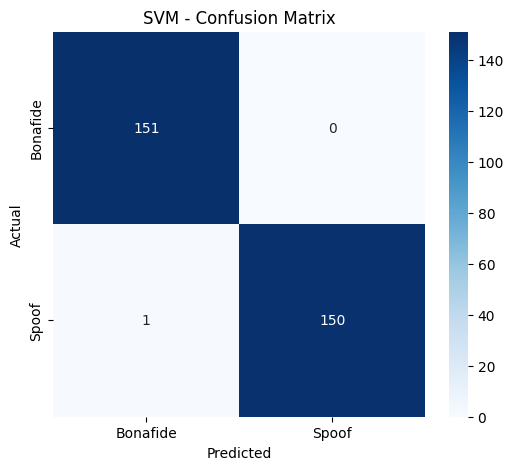

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    svm_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Bonafide", "Spoof"],
    yticklabels=["Bonafide", "Spoof"]
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
joblib.dump(
    svm_model,
    "/content/VoiceGuard_SVM_model.pkl"
)

joblib.dump(
    scaler,
    "/content/VoiceGuard_SVM_scaler.pkl"
)

svm_results_df.to_csv(
    "/content/VoiceGuard_SVM_results.csv",
    index=False
)

print("SVM model and results saved!")

SVM model and results saved!
